In [3]:
%pylab inline
import galsim
import numpy as np
import astropy.io.fits as pyfits

Populating the interactive namespace from numpy and matplotlib


In [19]:
# PSF preparation
ifield=0
# Basic parameters
ngrid       =   24
nrot        =   4
nx          =   nrot 
ny          =   1
ndata       =   nx*ny
scale       =   0.168
ngridTot    =   ngrid*nx
bigfft      =   galsim.GSParams(maximum_fft_size=10240)
flux_scaling=   2.587

# Get the psf and nosie information 
psfFname    =   'psf%04d.fits'%(ifield)
psfImg      =   galsim.fits.read(psfFname)
noiseHead   =   pyfits.getheader(psfFname)
psfInt      =   galsim.InterpolatedImage(psfImg,scale=scale,flux = 1.) 
# Get the shear information
g1          =   noiseHead['g1']
g2          =   noiseHead['g2']
fwhm        =   noiseHead['fwhm'] 
variance    =   noiseHead['var']
rescale     =   noiseHead['rescale']
ud          =   galsim.UniformDeviate(ifield*10000+1)
np.random.seed(ifield*10000+1)

In [20]:
# setup the galaxy image and the noise image
gal_image   =   galsim.ImageF(nx*ngrid,ny*ngrid,scale=scale)
gal_image.setOrigin(0,0)
var_image   =   galsim.ImageF(nx*ngrid,ny*ngrid,scale=scale)
var_image.setOrigin(0,0)

# Get the  galaxy generator      
# Load data
catName     =   'real_galaxy_catalog_best.fits'
directory   =   '/home/xiangchong/work/gw_ipmu/work/galsim_train/parent_best_processed/'
index       =   ifield%81400
# prepare the galaxies
rgc         =   galsim.RealGalaxyCatalog(catName,dir=directory)
rgcCat      =   rgc.cat
gal0    =   galsim.RealGalaxy(rgc,index=index,gsparams=bigfft)
gal0    *=  flux_scaling

for i in range(nrot):
    # Prepare the subimage
    ix      =   int(i%nx)
    iy      =   int(i/nx)
    b       =   galsim.BoundsI(ix*ngrid, (ix+1)*ngrid-1,iy*ngrid,(iy+1)*ngrid-1)
    sub_gal_image = gal_image[b]
    sub_var_image = var_image[b]
    if i%nrot==0:
        # Get the galaxy image
        gal     =   gal0
        # Rotate the galaxy
        ang     =   ud()*2.*np.pi * galsim.radians
        gal     =   gal.rotate(ang)
    else:
        gal     =   gal.rotate(1./nrot*np.pi*galsim.radians)
    final   =   gal.shear(g1=g1,g2=g2)
    # Shear the galaxy
    final     =   galsim.Convolve([psfInt,final],gsparams=bigfft)
    # Draw the galaxy image
    final.drawImage(sub_gal_image,method='no_pixel')
    galNoiVar   =   sub_gal_image.whitenNoise(final.noise)
    sub_var_image+=  galNoiVar
    print(galNoiVar)

8.24312900932905e-06
8.246357751473757e-06
8.243065039968647e-06
8.246322080388835e-06


In [21]:
rng = galsim.BaseDeviate(ifield)
max_variance=   np.max(var_image.array)
var_image   =   max_variance - var_image
vn          =   galsim.VariableGaussianNoise(rng,var_image)
gal_image.addNoise(vn)
unCorNoise  =   galsim.UncorrelatedNoise(max_variance,rng=rng,scale=scale)

In [22]:
corFname    =   'corTest.fits'
corNoise    =   galsim.getCOSMOSNoise(file_name=corFname,rng=ud,cosmos_scale=scale,variance=variance)
corNoise    =   corNoise-unCorNoise
corNoise.applyTo(gal_image)

galsim.Image(bounds=galsim.BoundsI(xmin=0, xmax=95, ymin=0, ymax=23), array=
array([[ 0.05683475,  0.02645602, -0.00054614, ...,  0.00733089,
         0.04266426, -0.05902747],
       [ 0.03229975, -0.00823834,  0.00793433, ..., -0.13095771,
         0.04645297,  0.03437654],
       [ 0.04419099,  0.07210471, -0.0807831 , ...,  0.04165998,
         0.01684673,  0.02482276],
       ...,
       [ 0.00363257,  0.12425121, -0.02922018, ...,  0.00803341,
         0.04038835,  0.01927893],
       [ 0.04181352,  0.03334753,  0.0130577 , ..., -0.00788616,
         0.0273163 ,  0.0690489 ],
       [ 0.03509862, -0.09033744,  0.08962659, ..., -0.07633074,
        -0.03954612,  0.03579887]], dtype=float32), wcs=galsim.OffsetWCS(0.168, galsim.PositionI(x=-1, y=-1), galsim.PositionD(x=0.0, y=0.0)))

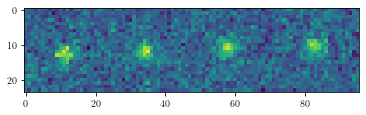

In [23]:
#corNoise.applyTo(gal_image)
plt.imshow(gal_image.array)

In [45]:
nsim=1000
img_all=np.zeros((nsim,ngrid,ngrid))
pow_all=np.zeros((nsim,ngrid,ngrid))
gal0    =   galsim.RealGalaxy(rgc,index=0,gsparams=bigfft)
final   =   gal0
#final   =   gal0.shear(g1=g1,g2=g2)
# Shear the galaxy
psfInt=galsim.Gaussian(fwhm=0.6,flux=1.,gsparams=bigfft)
final     =   galsim.Convolve([psfInt,final],gsparams=bigfft)
unCorNoise  =   galsim.UncorrelatedNoise(variance-var2,rng=rng,scale=scale)
for i in range(nsim):
    # Draw the galaxy image
    noi_image   =   galsim.ImageF(ngrid,ngrid,scale=scale)
    noi_image2  =   galsim.ImageF(ngrid,ngrid,scale=scale)
    final.drawImage(noi_image,method='no_pixel')
    final.drawImage(noi_image2,method='no_pixel')
    #var1=noi_image.whitenNoise(final.noise)
    var2=noi_image2.whitenNoise(final.noise)
    if i%300==0:
        print(var1,var2)
    #unCorNoise.applyTo(noi_image)
    a=noi_image.array
    b=noi_image2.array
    img_all[i]=a-b
    pow_all[i]=np.fft.fftshift(np.abs(np.fft.fft2(a))**2.)

1.503347612135987e-06 1.245252516316926e-06
1.503347612135987e-06 1.245252516316926e-06
1.503347612135987e-06 1.245252516316926e-06
1.503347612135987e-06 1.245252516316926e-06


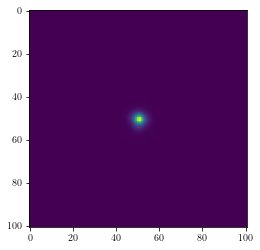

In [66]:
imshow(gal0.psf_image.array)

In [93]:
ngrid=32
gal0      =   galsim.RealGalaxy(rgc,index=0,gsparams=bigfft)
bigfft    =   galsim.GSParams(maximum_fft_size=10240)
psfInt    =   galsim.Gaussian(fwhm=0.8,flux=1.)#,gsparams=bigfft)
final     =   galsim.Convolve([psfInt,gal0])#,gsparams=bigfft)
noi_image =   galsim.ImageF(ngrid,ngrid,scale=0.168)
final.drawImage(noi_image,method='no_pixel')

galsim.Image(bounds=galsim.BoundsI(xmin=1, xmax=32, ymin=1, ymax=32), array=
array([[ 3.2040747e-03,  4.1994364e-03,  4.3926137e-03, ...,
         1.5475531e-03,  7.3959102e-04, -1.6695431e-04],
       [ 3.0026706e-03,  3.7664014e-03,  3.6522879e-03, ...,
        -4.2450259e-04, -1.0733966e-03, -1.9169452e-03],
       [ 3.2688407e-03,  3.8415932e-03,  3.3722387e-03, ...,
         1.2920480e-04, -4.8534377e-04, -1.5380160e-03],
       ...,
       [ 6.5833288e-03,  5.5453791e-03,  4.0902016e-03, ...,
         5.4342399e-04,  5.9065782e-04, -2.8114117e-05],
       [ 5.1471256e-03,  4.2217704e-03,  3.0159974e-03, ...,
         1.6637207e-03,  1.6976342e-03,  9.6298673e-04],
       [ 2.6985712e-03,  2.0387764e-03,  1.0831011e-03, ...,
         2.6914054e-03,  2.8110440e-03,  2.0719033e-03]], dtype=float32), wcs=galsim.PixelScale(0.168))

In [94]:
#a=gal0.gal_image.array
#a=gal0.psf_image.array
a=noi_image.array
ny,nx=a.shape
shiftx=(nx-ngrid)//2
shifty=(ny-ngrid)//2
b=np.zeros((ngrid,ngrid))
b=a[shifty:shifty+ngrid,shiftx:shiftx+ngrid]

In [95]:
pyfits.writeto('aaa.fits',np.fft.fftshift(np.abs(np.fft.fft2(b))**2.),overwrite=True)
pyfits.writeto('bbb.fits',b,overwrite=True)

In [46]:
img_ave=np.average(img_all,axis=0)
pow_ave=np.average(pow_all,axis=0)

1.110189428007453


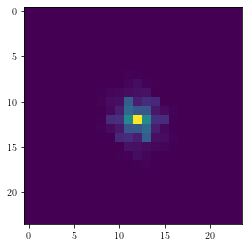

In [48]:
imshow(pow_ave)
print(np.var(pow_ave))
pyfits.writeto('bbb.fits',pow_all[0],overwrite=True)

In [21]:
noi_image   =   galsim.ImageF(ngrid,ngrid,scale=scale)
gal0    =   galsim.RealGalaxy(rgc,index=0,gsparams=bigfft)
final   =   gal0.shear(g1=g1,g2=g2)
# Shear the galaxy
final     =   galsim.Convolve([psfInt,final],gsparams=bigfft)
# Draw the galaxy image
final.drawImage(noi_image,method='no_pixel')

powMea=np.zeros((ngrid,ngrid))
num=0
for i in range(1000):
    corNoise.applyTo(noi_image2)
    noi_array=noi_image2.array
    powMea+=np.fft.fftshift(np.abs(np.fft.fft2(noi_array))**2.)
    num+=1